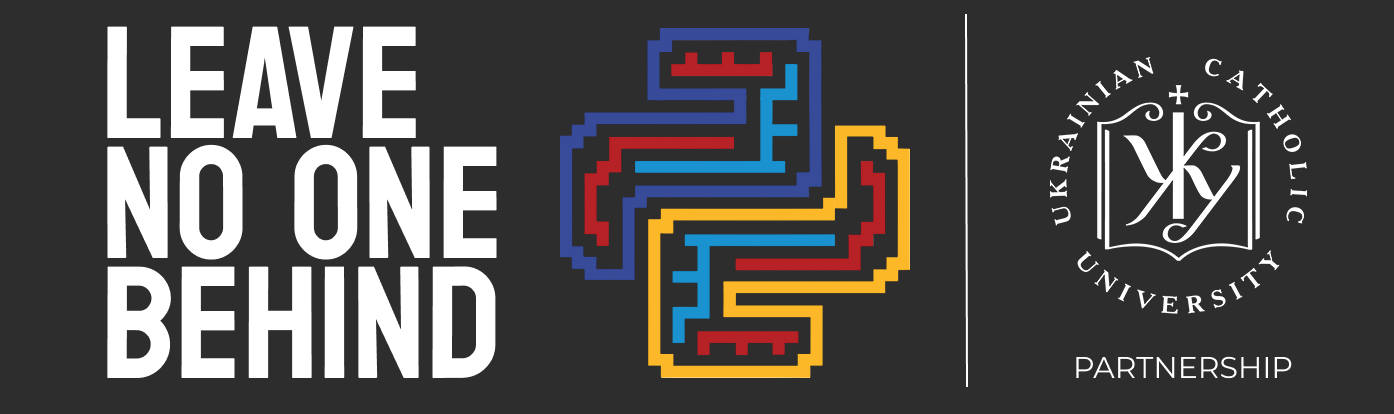

Перед Вами версія 1.0 навчальних матеріалів, що були створені командою Факультету прикладних наук Українського католицького університету в рамках освітнього проєкту ["Не залишити нікого осторонь"](https://www.facebook.com/leavenoonebehindpartnership/) 2024 року. Ми &mdash; Радомир Гусєв, Лідія Семсічко, Антон Валігурський, Максим Жук, Тетяна Захарченко &mdash; створювали його з любовʼю. Будемо вдячні, якщо наша праця буде завжди мати вказане авторство. Ліцензовано під [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)

Чарівного Вам кодування!

# Списки й кортежі

## Зміст

- [1. Послідовності](#sequences)
- [2. Спискові вирази](#list-comprehension)
- [3. Зрізи](#slices)
- [4. Змінюваність](#mutability)
- [5. Деструктивні та недеструктивні зміни](#destructive)
- [6. Сортування, обертання](#sort-reverse)
- [7. Інші методи](#methods)
- [8. Копіювання списків](#copying)

<a id="sequences"></a>
## 1. Послідовності

Ми зустрічали різні типи послідовностей, як-от списки чи стрічки. Хоч загалом називаємо послідовністю впорядковані набори елементів, у випадку Python є конкретний набір властивостей, які мають виконуватися, аби можна було назвати об'єкт послідовністю (як-от індексування, можливість брати зрізи (слайси), отримувати довжину тощо - детальніше [тут](https://docs.python.org/3/library/collections.abc.html#collections-abstract-base-classes)).

Серед вбудованих у мову послідовностей можна виділити такі:
- Стрічки (`str`)
- Діапазони (`range`)
- Списки (`list`)
- Кортежі (`tuple`)

Поговорімо детальніше про останні два.

Для початку нагадаємо способи створення цих типів:

### Кортежі

Ми можемо створювати кортежі:

1. Використавши круглі дужки () та безпосереднє перелічення елементів:

In [ ]:
print(f"{(1, 2) = }")
print(type((1, 2)))

(1, 2) = (1, 2)
<class 'tuple'>


При цьому зверніть увагу, що порожній кортеж містить лише дві дужки:

In [ ]:
type(())

tuple

Аби створити кортеж з одним елементом, потрібно використати наступний синтаксис: `a = (1,)` . Це необхідно, аби якось можна було розрізнити число в дужці від кортежа (наприклад, щоб у виразі `(1 + 2) + 3` перша частина інтерпретувалася як число:

In [ ]:
false_tuple = (1 + 2)
print(false_tuple, type(false_tuple))

true_tuple = (1 + 2,)
print(true_tuple, type(true_tuple))

3 <class 'int'>
(3,) <class 'tuple'>


2. Можна використовувати вбудовану функцію (насправді не функцію, але про це пізніше) `tuple()` без аргументів для створення порожнього кортежу або ж з аргументом, що є ітерованим, `iterable` (по-простому, можна поелементно перебрати його вміст).

In [ ]:
print(f"{tuple() = }")
print(f"{tuple((1, 2, 3)) = }")
print(f"{tuple([1, 2, 3]) = }")
print(f"{tuple(range(4)) = }")
print(f"{tuple('123') = }")

tuple() = ()
tuple((1, 2, 3)) = (1, 2, 3)
tuple([1, 2, 3]) = (1, 2, 3)
tuple(range(4)) = (0, 1, 2, 3)
tuple('123') = ('1', '2', '3')


Кортежі між собою можна додавати, що призведе до їх конкатенації:

In [ ]:
(1, 2) + ('2', '3')

(1, 2, '2', '3')

Відповідно можна і множити на цілі числа, що є відповідним процесу додавання певну кількість разів:

In [ ]:
(1, 2)*3

(1, 2, 1, 2, 1, 2)

### Списки

Досить схожі способи і в списків, але вже використовуючи відповідно квадратні дужки `[]` та вбудовану функцію (не зовсім) `list()`.

In [ ]:
print(['a', 1])
print([])
print(list())

['a', 1]
[]
[]


In [ ]:
print(f"{list(('інша', 'колекція')) = }")
print(f"{list(['інша', 'колекція']) = }")
print(f"{list(range(4)) = }")
print(f"{list('Інша колекція') = }")

list(('інша', 'колекція')) = ['інша', 'колекція']
list(['інша', 'колекція']) = ['інша', 'колекція']
list(range(4)) = [0, 1, 2, 3]
list('Інша колекція') = ['І', 'н', 'ш', 'а', ' ', 'к', 'о', 'л', 'е', 'к', 'ц', 'і', 'я']


In [ ]:
[1, 2] * 3

[1, 2, 1, 2, 1, 2]

### Індексування

У Python, як і в багатьох інших мовах, індексація починається з `0`. Тобто перший по порядку елемент матиме індекс `0`, другий – `1`, третій – `2`...

In [ ]:
print(f"{['a', 'b', 'c'][0] = }")
print(f"{['a', 'b', 'c'][1] = }")
print(f"{['a', 'b', 'c'][2] = }")

['a', 'b', 'c'][0] = 'a'
['a', 'b', 'c'][1] = 'b'
['a', 'b', 'c'][2] = 'c'


Якщо задати індекс більший за максимальний, то виникне помилка `IndexError` (помилка індексу):

In [ ]:
print(f"{['a', 'b', 'c'][3] = }")

IndexError: list index out of range

Якщо ж задати менше за нуль, то Python почне рахувати з кінця послідовності. Наприклад, якщо є список з п'яти елементів, то `[-1]` видасть останній (п'ятий) елемент, а `[-2]` – передостанній (четвертий):

In [ ]:
print(f"{('a', 'b', 'c', 'd', 'e')[-1] = }")
print(f"{('a', 'b', 'c', 'd', 'e')[-2] = }")

('a', 'b', 'c', 'd', 'e')[-1] = 'e'
('a', 'b', 'c', 'd', 'e')[-2] = 'd'


Так само індексація працює і зі стрічками:

In [ ]:
print(f"{'abcde'[-1] = }")
print(f"{'abcde'[-2] = }")

'abcde'[-1] = 'e'
'abcde'[-2] = 'd'


Наглядніше можна побачити індекси (додатні та від'ємні) стрічки `Python` у наступній таблиці:

| P  | y  | t  | h  | o  | n  |
| -- | -- | -- | -- | -- | -- |
| 0  | 1  | 2  | 3  | 4  | 5  |
| -6 | -5 | -4 | -3 | -2 | -1 |

<a id="list-comprehension"></a>
## 2. Спискові вирази

Однак є ще цікавіший спосіб створення списків – **спискові вирази**.

Пригадаймо, як ми раніше робили перетворення всіх елементів списку (як-от підняття до квадрату):

In [ ]:
original = [-4, 5, 0, 9]

squares = []
for i in original:
    squares.append(i**2)
print(squares)

[16, 25, 0, 81]


Таке ж перетворення можна виконати одним рядком:

In [ ]:
original = [-4, 5, 0, 9]

squares = [i**2 for i in original]
print(squares)

[16, 25, 0, 81]


У частині `for i in original` ми по суті створюємо такий же цикл, як і раніше. Вираз перед цією частиною (у цьому випадку `i**2`) буде виконаний на кожній ітерації циклу, а результат виконання доданий до нового.

Можна писати й інші вирази замість підняття до квадрату – підійдуть будь-які, що вийде записати в один рядок:

In [ ]:
original = [4, 5, 0, 9]

squares = [(i**2, i**0.5) for i in original]
print(squares)

[(16, 2.0), (25, 2.23606797749979), (0, 0.0), (81, 3.0)]


Тут, наприклад, ми перетворили кожен елемент першого списку в кортеж:
- перший елемент - квадрат числа,
- другий - корінь квадратний.

Можна навіть робити вкладені цикли. Так, наприклад, замість такої вкладеності:

In [ ]:
original = [
    [1, 2, 3],
    [4, 5, 6],
]

squares = []
for i in original:
    for j in i:
        squares.append(j**2)
print(squares)

[1, 4, 9, 16, 25, 36]


Можна використати списковий вираз:

In [1]:
original = [
    [1, 2, 3],
    [4, 5, 6],
]

squares = [j**2 for i in original for j in i]
print(squares)

[1, 4, 9, 16, 25, 36]


У спискових виразах також часто буває корисним такий синтаксис:

In [ ]:
number = -16
square_root = number**0.5 if number >= 0 else None
print(square_root)

number = 16
square_root = number**0.5 if number >= 0 else None
print(square_root)

None
4.0


Конструкція `true_value if condition else false_value` є тернарним оператором у Python.

Це є коротка нотація для `if-else` конструкції:

In [ ]:
number = -16
if number >= 0:
    square_root = number**0.5
else:
    square_root = None
print(square_root)

None


Замість чотирьох рядочків тепер необхідно писати лише один - для таких коротких виразів це дуже спрощує життя!

Звісно, не варто використовувати такий синтаксис для складніших перевірок - нічого не буде ясно:

In [ ]:
number = -16
print((number**3 - 4 * number**2 + number**0.5 - 14) / 2 if number % 3 != 1 and number > 14 or number < 0 and number % 3 == 1 else (2 * number**3 + 3 * number + 2 * number**0.5 - 1) / 4)

(-2060.25+2j)


Застосувавший такий синтаксис до спискових виразів, можна для деяких елементів отримувати одні значення, а для інших - інші:

In [ ]:
original = [1, 2, 3, 4]

result = [i**2 if i % 2 else i**3 for i in original]
print(result)

[1, 8, 9, 64]


Такий код, наприклад, усі непарні числа підніме до квадрату, а парні до кубу.

Якщо ж додати `if <вираз>` (без частини `else`) **після** частини `for`, то можна буде фільтрувати значення, що не підпадають під вираз:

In [ ]:
original = [1, 2, 3, 4, 5, 6]

even = [i for i in original if i % 2 == 0]
print(even)

[2, 4, 6]


Зверніть увагу, що якщо є лише умова `if`, то вона ставиться після `for`, а якщо повноцінно `if-else`, то перед.

Варто тільки бути обережними з круглими дужками, адже такий вираз призначений для іншої цілі, ніж створення кортежа:

In [ ]:
original = [1, 2, 3, 4, 5, 6]

even = (i for i in original if i % 2 == 0)
print(even)

<generator object <genexpr> at 0x7f399a2bae90>


Якщо захочеться таки отримати кортеж, то потрібно буде викликати `tuple()` на такому виразі:

In [ ]:
original = [1, 2, 3, 4, 5, 6]

even = tuple(i for i in original if i % 2 == 0)
print(even)

(2, 4, 6)


<a id="slices"></a>
## 3. Зрізи

Пригадаймо, як працює `range`. У його повній формі в нього є три параметри:
- початкова позиція,
- кінцева позиція,
- крок.

Так, `range(4, 16, 3)` буде видавати кожен третій елемент між `4` (включно) та `16` (не включно):

In [ ]:
[i for i in range(4, 16, 3)]

[4, 7, 10, 13]

А `range(10, 3, -2)` видаватиме кожен другий елемент, починаючи з `10` (включно) та йдучи у зворотну сторону до `4` (не включно):

In [ ]:
[i for i in range(10, 4, -2)]

[10, 8, 6]

Схожим чином можна використати синтаксис `[<початок>:<кінець>:<крок>]` (**зріз** чи **слайс**) на послідовності, аби отримати елементи на позиціях, починаючи з `<початку>`, закінчуючи `<кінцем>` та переходячи через `<крок>` елементів щоразу.

Наприклад, аби отримати елементи з третього (включно) по десятий (не включно), пропускаючи по два (тобто брати кожен другий), можна скористатися `[3:10:2]`:

In [ ]:
alphabet_start = ["a", "b", "c", "d", "e", "f", "g", "h", "i", "j", "k", "l", "m", "n", "o"]
alphabet_start[3:10:2]

['d', 'f', 'h', 'j']

Третій елемент - `"d"`, через один після нього (п'ятий) - `"f"`. За ними через один слідують `"h"` (сьомий) та `"j"` (дев'ятий).

Аналогічно можна йти у протилежний бік, задавши від'ємний крок. Так, `[9, 2, -2]` отримає ту ж послідовність, але у зворотному порядку:

In [ ]:
alphabet_start = ["a", "b", "c", "d", "e", "f", "g", "h", "i", "j", "k", "l", "m", "n", "o"]
alphabet_start[9:2:-2]

['j', 'h', 'f', 'd']

Оскільки зрізи, як і `range` включають перше число і не включають друге, то при зміні `[3, 10)` на зворотне довелося поставити `[9, 2)`, аби отримати ті ж індекси.

Така конструкція аналогічно працює і для кортежів й стрічок:

In [ ]:
alphabet_start_tuple = ("a", "b", "c", "d", "e", "f", "g", "h", "i", "j", "k", "l", "m", "n", "o")
alphabet_start_str = "abcdefghijklmno"

print(f"{alphabet_start_tuple[9:2:-2] = }")
print(f"{alphabet_start_str[9:2:-2] = }")

alphabet_start_tuple[9:2:-2] = ('j', 'h', 'f', 'd')
alphabet_start_str[9:2:-2] = 'jhfd'


Якщо не вказати `<початок>`, то за замовчуванням зріз буде від самого початку послідовності. Якщо не вказати `<кінець>` - до кінця послідовності. Якщо ж не вказати крок, то він буде рівний `1`.

Наприклад, такий зріз буде з третього елемента до кінця, з кроком 2 (кожен другий):

In [ ]:
alphabet_start_str = "abcdefgh"
alphabet_start_str[3::2]

'dfh'

А `[::-1]` не має перших двох, отже буде від початку до кінця послідовності. Крок `-1` вказує, що необхідно йти в протилежному напрямку - отже, вийде обернена послідовність:

In [ ]:
alphabet_start = ["a", "b", "c", "d", "e", "f", "g", "h"]
alphabet_start[::-1]

['h', 'g', 'f', 'e', 'd', 'c', 'b', 'a']

А такий із шостого до другого, у зворотному напрямку:

In [ ]:
alphabet_start_str = "abcdefgh"
alphabet_start_str[6:2:-1]

'gfed'

І такий із першого до кінця:

In [ ]:
alphabet_start = ["a", "b", "c", "d", "e", "f", "g", "h"]
alphabet_start[1::]

['b', 'c', 'd', 'e', 'f', 'g', 'h']

У випадках, коли крок `1` можна навіть не додавати останньої двокрапки, а просто писати `[<початок>:<кінець>]`:

In [ ]:
alphabet_start = ["a", "b", "c", "d", "e", "f", "g", "h"]
alphabet_start[1:]

['b', 'c', 'd', 'e', 'f', 'g', 'h']

In [ ]:
alphabet_start = ["a", "b", "c", "d", "e", "f", "g", "h"]
alphabet_start[:4]

['a', 'b', 'c', 'd']

❔ Погляньте на такі вирази та подумайте, як вони так працюють. Після цього перевірте!

In [2]:
"abcdefg"[1:1]

''

In [3]:
"abcdefg"[1:3:-1]

''

In [4]:
["a", "b", "c", "d", "e"][2:0]

[]

In [5]:
("a", "b", "c", "d", "e")[2:-1]

('c', 'd')

In [6]:
"abcdefg"[2::-1]

'cba'

In [7]:
"abcdefg"[::]

'abcdefg'

Ви, напевно, вже чули, що кортеж відрізняється від списку тим, що він незмінюваний - подивімося, що це означає на практиці.

Перш за все, не можна переприсвоювати елементи через індекс після створення:

In [ ]:
sample_list = [1, 2]
sample_list[1] = 3
sample_list

[1, 3]

In [ ]:
sample_tuple = (1, 2)
sample_tuple[1] = 3
sample_tuple

TypeError: 'tuple' object does not support item assignment

По-друге, не можна додавати нових елементів:

In [ ]:
sample_list = [1, 2]
sample_list.append(3)
sample_list

[1, 2, 3]

In [ ]:
sample_tuple = (1, 2)
sample_tuple.append(3)
sample_tuple

AttributeError: 'tuple' object has no attribute 'append'

Заборонені й інші способи додавання, видалення чи переприсвоєння елементів. Однак можна створювати нові кортежі зі зміненими даними:

In [ ]:
sample_tuple = (1, 2)
sample_tuple = sample_tuple + (3, 4)
sample_tuple += (5,)
sample_tuple

(1, 2, 3, 4, 5)

Насправді кортежі й стрічки досить схожі, і зміни створюють нові об'єкти:

In [ ]:
sample_str = "a"
print(id(sample_str))
sample_str += "ab"
print(id(sample_str))

4346363992
4412798384


In [ ]:
sample_tuple = (1, 2)
print(id(sample_tuple))
sample_tuple = sample_tuple + (3, 4)
print(id(sample_tuple))
sample_tuple += (5,)
print(id(sample_tuple))
sample_tuple

4412905856
4412835616
4412836736


(1, 2, 3, 4, 5)

Як бачимо, після кожної зміни `id` (ідентифікатор) об'єкта змінюється - отже з'являються взагалі нові об'єкти. Натомість, якщо поглянути на випадок зі списками:

In [ ]:
sample_list = [1, 2]
print(id(sample_list))
sample_list.append(3)
print(id(sample_list))
sample_list += [4]
print(id(sample_list))
sample_list

4397235072
4397235072
4397235072


[1, 2, 3, 4]

То виявиться, що весь цей час об'єкт залишався той самий, але до нього додавалися нові елементи. Об'єкт списку залишається тим самим, допоки ми його змінюємо, а не переприсвоюємо.

**Зверніть увагу**, що `+=` не переприсвоює список! Не завжди `a +=...` та `a = a +...` - одне і те ж:

In [ ]:
sample_list = [1, 2]
print(id(sample_list))
sample_list += [3]
print(id(sample_list))
sample_list = sample_list + [4]
print(id(sample_list))
sample_list

4412820928
4412820928
4412796096


[1, 2, 3, 4]

`sample_list += [3]` додає елементи з другого списку до першого (тож ідентифікатор об'єкта не змінюється), тоді як `sample_list = sample_list + [4]` створює новий список, який має елементи з `sample_list` та `[4]`, після чого присвоює `sample_list` значення того списку:

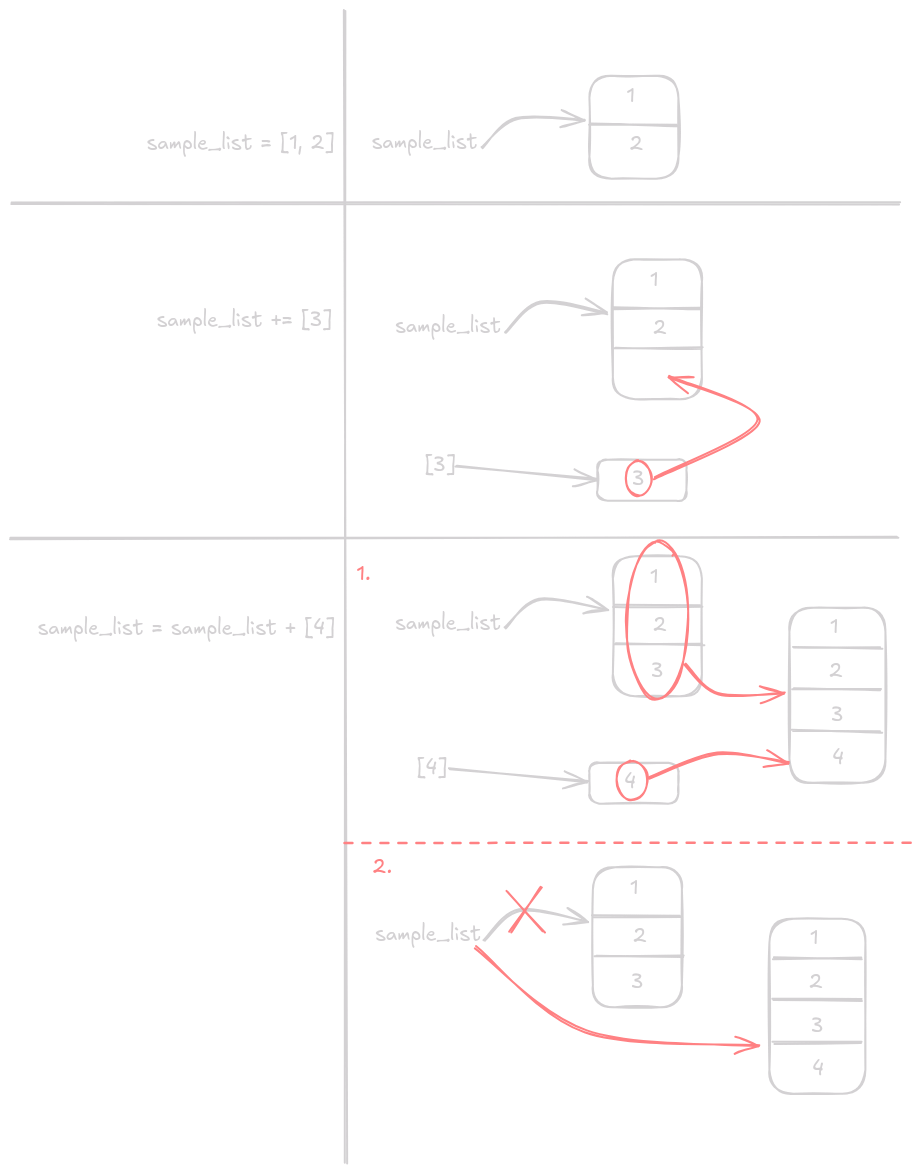

Ще цікавіше стає, якщо присвоїти іншій змінній цей самий список:

In [ ]:
list1 = [1]
list2 = list1
print(list1, list2)
print(id(list1), id(list2))

[1] [1]
4397579072 4397579072


Як бачимо, не тільки значення списків однакові, а й сам об'єкт один і той самий (однакові ідентифікатори)! Тобто обидві змінні посилаються на один і той самий об'єкт:

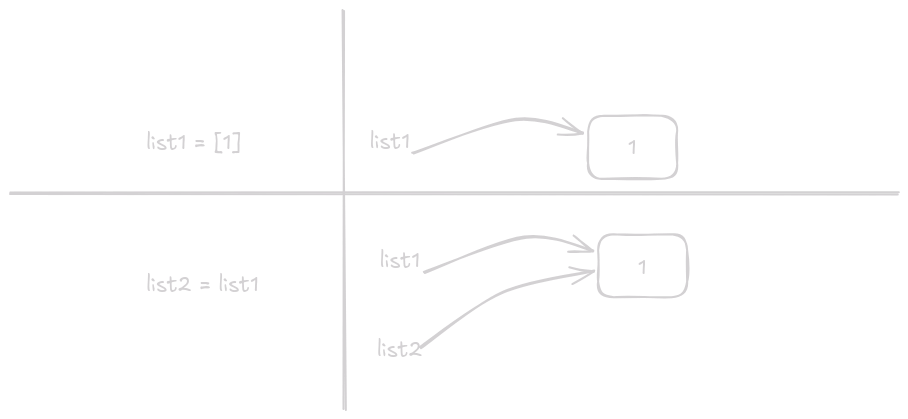

Це означає, що якщо ми захочемо змінити `list1` (а точніше об'єкт, на який `list1` посилається), то ці ж зміни буде видно зі змінної `list2`:

In [ ]:
list1.append(2)
print(list1, list2)

[1, 2] [1, 2]


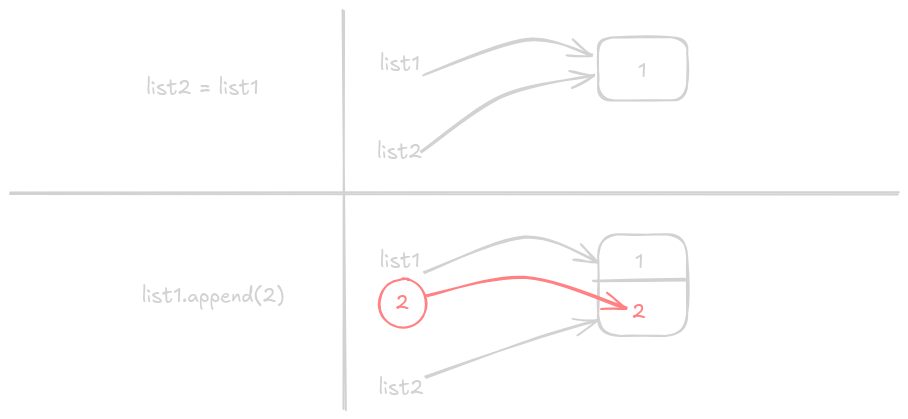

Це особливо збиває з пантелику, якщо передавати список аргументом у функцію:

In [ ]:
def list_plus_2(lst: list) -> list:
    lst.append(2)
    return lst

list1 = [1]
list2 = list_plus_2(list1)

print(list1, list2)
print(id(list1), id(list2))

[1, 2] [1, 2]
4412796544 4412796544


Для того, аби розбирати складніші випадки, дуже корисним може бути [pythontutor](https://pythontutor.com/visualize.html#mode=edit). Тут можна написати код, нажати на "Visualize Execution" та рядок за рядком дивитися зміни.

Справа ж показує панель із змінними та об'єктами, на які вони посилаються:

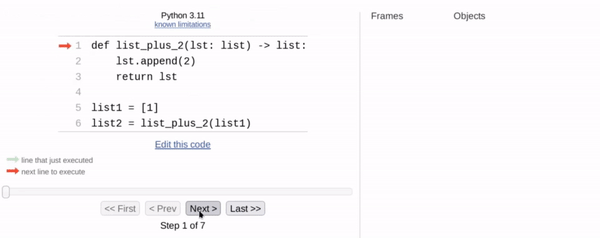


Бачимо, наприклад, що при виклику функції відбулося присвоєння `lst = list1`, і вони посилаються на один і той же об'єкт. Тож при додаванні до об'єкту `lst` двійки, ми додаємо до того ж об'єкту, на який посилається `list1`. Червоною стрілкою же виділений рядок, який зараз виконується.

Після повернення з функції `list2` присвоїться значення `lst` - `list2` посилатиметься на той же об'єкт, що й `lst` - тобто і на той, що `list1`.

Якщо складно зрозуміти, які зміни відбуваються з об'єктами, то обов'язково пробуйте виконати рядок за рядком на цьому сайті!

<a id="destructive"></a>
## 5. Деструктивні та недеструктивні зміни

Як ми могли побачити, якісь способи змінюють існуючий об'єкт, а якісь створюють новий. Було би добре чітко їх розрізняти за назвою.

Дії, що не змінюють початковий об'єкт називають **недеструктивними**. Ті ж, що змінюють - **деструктивними**.

Ми вже знаємо деякі деструктивні дії:

In [ ]:
lst = [1, 2, 3]
lst.append(4)
lst += [5]
print(lst)

[1, 2, 3, 4, 5]


після яких змінюється початковий об'єкт, та деякі недеструктивні:

In [ ]:
list1 = [1, 2, 3]
list2 = list1 + [4]
print(f"{list2 = }")
list3 = list1[:2]
print(f"{list3 = }")
print(f"{list1 = }")

list2 = [1, 2, 3, 4]
list3 = [1, 2]
list1 = [1, 2, 3]


після яких початковий об'єкт залишається незмінним.

Однак є багато інших методів, функцій та інших дій, і варто одразу пам'ятати, які з них змінюють початковий список, а які ні.

Більшість можна запам'ятати таким чином: якщо дія *повертає* новий об'єкт, то вона *недеструктивна* - якщо *не повертає* нічого, то *деструктивна*.

Наприклад, `lst.append(4)` не повертає нового списку, і ми нічому не присвоюємо значення. Якщо ж вивести результат виконання, то побачимо, що це `None` - отже *деструктивна* дія:

In [ ]:
lst = [1]
result = lst.append(4)
print(result)

None


Натомість `lst + [4]` повертає новий список, який можемо чомусь присвоїти - *недеструктивна* дія:

In [ ]:
lst = [1]
result = lst + [4]
print(result)

[1, 4]


Тож звертайте на це увагу, коли будемо дивитися різні дії над списками.

<a id="sort-reverse"></a>
## 6. Сортування, обертання

### Сортування

Часто може хотітися посортувати елементи послідовності. Для цього можуть підійти метод `.sort()` та функція `sorted()`:

In [ ]:
sample_list1 = [42, 0.69, 1337, 12, -1, float("infinity")]
sample_list1.sort()

sample_list1

[-1, 0.69, 12, 42, 1337, inf]

In [ ]:
sample_list2 = [42, 0.69, 1337, 12, -1, float("infinity")]
sorted_list = sorted(sample_list)

sorted_list

[-1, 0.69, 12, 42, 1337, inf]

Бачимо, що значення `sample_list.sort()` нічому не присвоюється - *деструктивна* дія. А от значення функції, що приймає список і повертає посортований, присвоюється новій змінній - *недеструктивна*. Можемо перевірити:

In [ ]:
print(sample_list1)
print(sample_list2)

[-1, 0.69, 12, 42, 1337, inf]
[42, 0.69, 1337, 12, -1, inf]


Отже, `sorted()` не змінив значення оригінального списку.

Також можемо побачити ще одну закономірність:
- Якщо виконується функція, яка приймає аргументом послідовність - *недеструктивна*,
- якщо це метод на послідовності (через крапку) - *деструктивна*.

Ще одна властивість *недеструктивних* дій - їх можна виконувати на незмінюваних типах. До прикладу, `.sort()` не вийде застосувати на кортежі, а от `sorted()` - вийде, адже він не змінює існуючого об'єкта, а створює новий:

In [ ]:
print(sorted((3, 1, 2)))

[1, 2, 3]


In [ ]:
(3, 1, 2).sort()

AttributeError: 'tuple' object has no attribute 'sort'

### Обертання

Інша часта дія - обертання послідовності (аби перший елемент став останнім, а останній першим). Для цього використовують метод `.reverse()` та функцію `reversed()`:

In [ ]:
sample_list1 = [2, 1, 3, 5]
sample_list1.reverse()

sample_list1

[5, 3, 1, 2]

Однак варто зазначити, що `reversed` повертає спеціальний об'єкт, а не список. По ньому, проте, можна пройтися ітерацією (наприклад, з допомогою спискового виразу):

In [ ]:
sample_list1 = [2, 1, 3, 5]
reversed_list = reversed(sample_list1)

print(reversed_list)
print([i for i in reversed_list])

[5, 3, 1, 2]


З цим об'єктом також спрацює обгортання в `list()`:

In [ ]:
reversed_list = reversed(sample_list1)
print(list(reversed_list))

[5, 3, 1, 2]


❔ Подумайте, яка з цих дій *деструктивна*, а яка ні, а також яка з них буде працювати з кортежами.

❔ Пригадайте, як обертати послідовності з допомогою зрізів (слайсів).

<a id="methods"></a>
## 7. Інші методи

### `insert`

Що як захочеться додати елемент не в кінець списку (як з `append`), а в середину? Тоді можна скористатися `insert`:

In [ ]:
sample_list = [2, 1, 3, 5]
sample_list.insert(1, 0)

sample_list

[2, 0, 1, 3, 5]

- Перший аргумент - індекс, в який потрібно вставляти елемент (у цьому випадку на індекс `1`);
- другий - сам елемент, який потрібно вставити в це місце (`0`).

Таким чином ми в позицію `1` - після першого елемента - вставили значення `0`.

Ця дія нічого не повертає та є методом - *деструктивна*, початковий список змінився.

### `extend`

Якщо хочеться додати одразу кілька елементів, можна скористатися `extend`:

In [ ]:
sample_list = [2, 1, 3, 5]
sample_list.extend(["4", "9", "0"])

sample_list

[2, 1, 3, 5, '4', '9', '0']

Ви могли помітити, що працює схоже до `+=`:

In [ ]:
sample_list = [2, 1, 3, 5]
sample_list += ["4", "9", "0"]

sample_list

[2, 1, 3, 5, '4', '9', '0']

Так і є, і обидві дії *деструктивні*.

Аби виконати розширення списку *недеструктивно* можна скористатися додаванням:

In [ ]:
sample_list = [2, 1, 3, 5]
extended = sample_list + ["4", "9", "0"]

print(f"{extended = }")
print(f"{sample_list = }")

extended = [2, 1, 3, 5, '4', '9', '0']
sample_list = [2, 1, 3, 5]


### Видалення елемента

Аби видалити елемент на певній позиції, можна скористатися `pop()`:

In [ ]:
sample_list = ["2", "1", "3", "5"]
sample_list.pop(2)

sample_list

['2', '1', '5']

Ось позиції елементів:
- "2" - 0
- "1" - 1
- "3" - 2
- "5" - 3

Ми видалили елемент з індексом 2 - отже це елемент "3".

Ця дія, звісно, *деструктивна*, оскільки видаляє елементи з існуючого списку. Однак ця дія також повертає елемент, який вона щойно видалила. У цьому випадку вона видалила "3", тож і повернула "3":

In [ ]:
sample_list = ["2", "1", "3", "5"]
print(f"{sample_list.pop(2) = }")

sample_list

sample_list.pop(2) = '3'


['2', '1', '5']

Також можна видалити елемент за значенням, а не індексом. Наприклад, аби видалити першу "3" у списку, можна використати `.remove("3")`:

In [ ]:
sample_list = ["2", "1", "3", "5", "3"]
sample_list.remove("3")

sample_list

['2', '1', '5', '3']

### Очищення списку

Якщо хочеться повністю очистити список, то можна скористатися `.clear()`:

In [ ]:
sample_list1 = ["2", "1", "3", "5"]
sample_list2 = sample_list1
sample_list2.clear()

print(f"{sample_list1 = }")
print(f"{sample_list2 = }")

sample_list1 = []
sample_list2 = []


Щоб виконати дію *недеструктивно*, можна переприсвоїти значення на порожній список:

In [ ]:
sample_list1 = ["2", "1", "3", "5"]
sample_list2 = sample_list1
sample_list2 = []

print(f"{sample_list1 = }")
print(f"{sample_list2 = }")

sample_list1 = ['2', '1', '3', '5']
sample_list2 = []


### Знаходження позиції елемента

Час від часу може бути корисно знайти позицію елемента в послідовності. `<послідовність>.index(<елемент>)` знайде позицію першого входження елемента в послідовність:

In [ ]:
[1, 1, 3, 2, 4, 0, 2].index(2)

3

Вперше `2` з'являється на третій позиції.

Також можна шукати елемент від якогось індексу до якогось. Для цього можна вказати опційний другий (start) та третій аргумент (end).

In [ ]:
[1, 1, 3, 2, 4, 0, 2].index(2, 4)

6

In [ ]:
[1, 1, 3, 2, 4, 0, 2].index(2, 4, 5)

ValueError: 2 is not in list

### Знаходження кількості елементів

Для того, аби знайти, скільки разів певний елемент трапляється в послідовності можна скористатися `<послідовність>.count(<елемент>)`:

In [ ]:
(1, 1, 4, 2, 1, 9, -1).count(1)

3

Бачимо, що число `1` трапляється тричі в кортежі.

<a id="copying"></a>
## 8. Копіювання списків

Розуміючи, що багато методів змінюють існуючий об'єкт, а не створюють новий, часто хочеться уникати ситуацій, коли дві змінні посилаються на один і той же об'єкт. Наприклад у цій ситуації, коли хочемо отримати новий список, що не має першої сімки:

In [ ]:
ordinary_list = [13, 3, 7, 23, 7, 42]

# Те ж посилання
tmp_list = ordinary_list

tmp_list.remove(7)
print(f"{tmp_list = }")
print(f"{ordinary_list = }")

tmp_list = [13, 3, 23, 7, 42]
ordinary_list = [13, 3, 23, 7, 42]


Після цих дій також змінений `ordinary_list`, адже вони посилаються на один і той же об'єкт.

Для того, аби `tmp_list` насправді був копією початкового списку, а не буквально тим самим об'єктом, використовують різні техніки копіювання.

Серед найпростіших - створити список, і через `for` вручну додати всі елементи з першого списку:

In [ ]:
ordinary_list = [13, 3, 7, 23, 7, 42]

# Копіювання
tmp_list = []
for i in ordinary_list:
    tmp_list.append(i)

tmp_list.remove(7)
print(f"{tmp_list = }")
print(f"{ordinary_list = }")

tmp_list = [13, 3, 23, 7, 42]
ordinary_list = [13, 3, 7, 23, 7, 42]


Початковий список не змінився, оскільки `tmp_list` не має ніякої прив'язки до об'єкта `ordinary_list` - ми вручну кожен елемент перенесли. Ось як це показує [pythontutor](https://pythontutor.com/visualize.html#mode=edit):

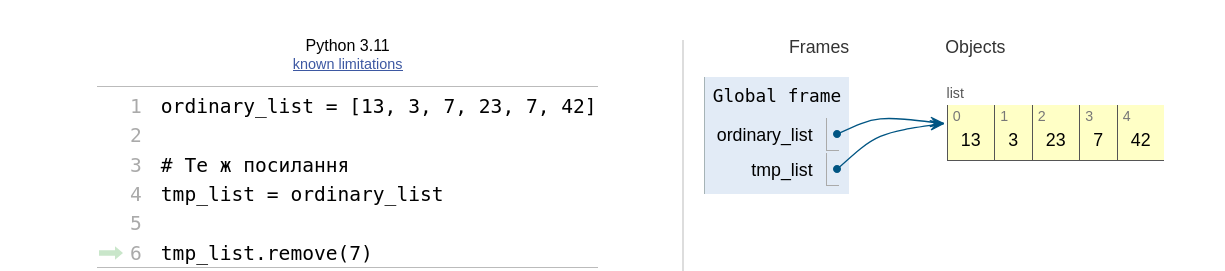 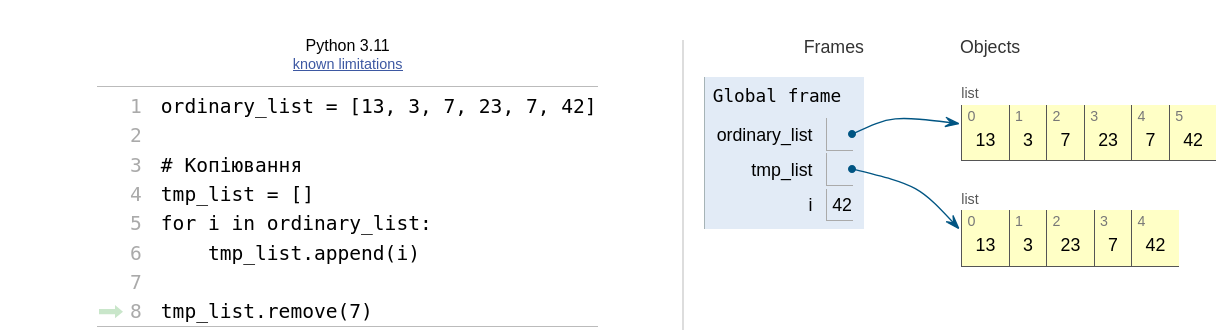

Є ще декілька способів скопіювати простіше. Наприклад, можна використати списковий вираз замість повного циклу `for`:

In [ ]:
ordinary_list = [13, 3, 7, 23, 7, 42]
ordinary_list = [13, 3, 7, 23, 7, 42]

# Копіювання
tmp_list = [i for i in ordinary_list]

tmp_list.remove(7)
print(f"{tmp_list = }")
print(f"{ordinary_list = }")

tmp_list = [13, 3, 23, 7, 42]
ordinary_list = [13, 3, 7, 23, 7, 42]


Також можна скористатися зрізом від нульового до останнього елемента, з кроком `1`:

In [ ]:
ordinary_list = [13, 3, 7, 23, 7, 42]

# Копіювання
tmp_list = ordinary_list[:]

tmp_list.remove(7)
print(f"{tmp_list = }")
print(f"{ordinary_list = }")

tmp_list = [13, 3, 23, 7, 42]
ordinary_list = [13, 3, 7, 23, 7, 42]


Аналогічно можна схитрувати застосувавши функцію `list()`

In [ ]:
ordinary_list = [13, 3, 7, 23, 7, 42]

# Копіювання
tmp_list = list(ordinary_list)

tmp_list.remove(7)
print(f"{tmp_list = }")
print(f"{ordinary_list = }")

tmp_list = [13, 3, 23, 7, 42]
ordinary_list = [13, 3, 7, 23, 7, 42]


А також просто скористатися вбудованим методом `copy()`

In [ ]:
ordinary_list = [13, 3, 7, 23, 7, 42]

# Копіювання
tmp_list = ordinary_list.copy()

tmp_list.remove(7)
print(f"{tmp_list = }")
print(f"{ordinary_list = }")

tmp_list = [13, 3, 23, 7, 42]
ordinary_list = [13, 3, 7, 23, 7, 42]


### Вкладені списки

Складнішою ситуація стає, якщо всередині списку є інші списки. Погляньмо спочатку, що відбувається, якщо не робити копіювання:

In [ ]:
nested_list = [[0]]

# Копіювання
new_list = nested_list

new_list[0].append(1)
print(f"{new_list = }")
print(f"{nested_list = }")

new_list = [[0, 1]]
nested_list = [[0, 1]]


Погляньмо, як це показує [pythontutor](https://pythontutor.com/visualize.html#mode=edit):

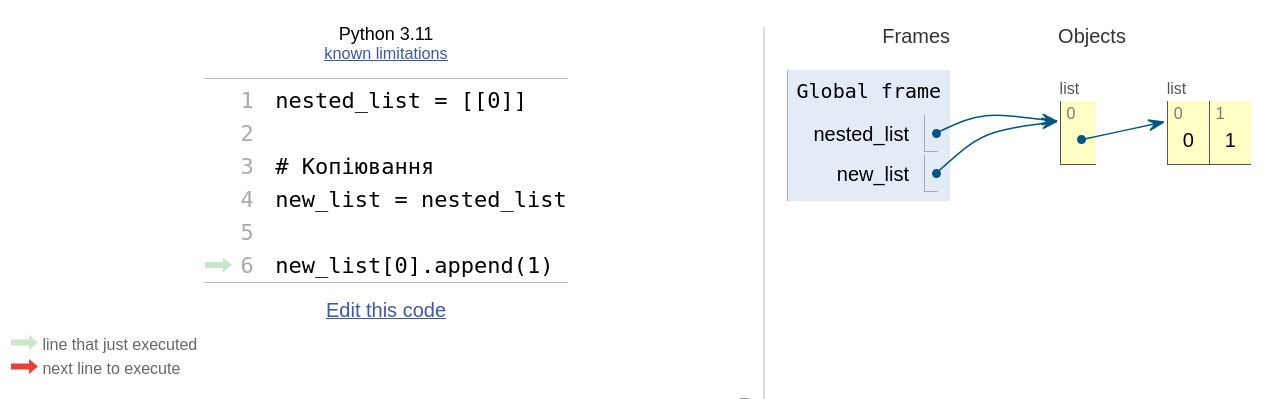

`nested_list` та `new_list` посилаються на один і той же об'єкт, в якого нульовий елемент має посилання на інший список. І, звісно, якщо `nested_list` та `new_list` посилаються на один і той же об'єкт, то й `nested_list[0]` та `new_list[0]` посилаються на один і той же список.

Однак якщо скопіювати `nested_list`, то скопіюється тільки посилання на інший список, а не сам інший список:


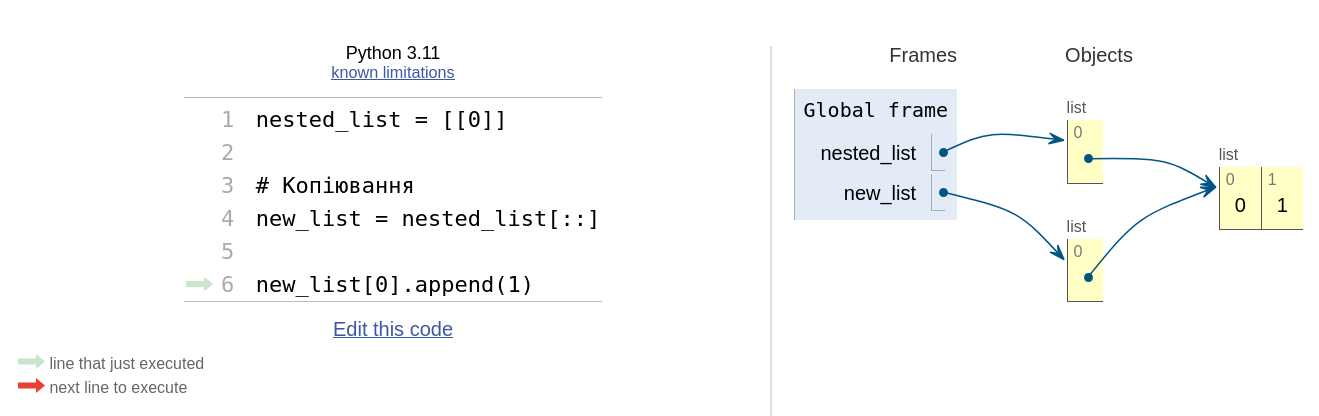

Бачимо, що зовнішній список скопіювався. Однак той об'єкт, на який посилається перший елемент - ні.

❔ Спробуйте різні варіації на [pythontutor](https://pythontutor.com/visualize.html#mode=edit): замінити нульовий елемент на інший, змінити всередині об'єкт, на який посилається нульовий елемент тощо.<br/>
Наприклад, якщо зробити `new_list[0] = []`, то що буде з `nested_list[0]`? А якщо `new_list[0][0] = 0`? Подивіться на візуалізацію справа та подумайте, які об'єкти повністю копіюються, а на які тільки копіюються посилання.

Для таких ситуацій, коли одні змінювані об'єкти знаходяться в інших, використовують модуль `copy`.

In [ ]:
import copy

Він має дві важливі функції: `copy()` та `deepcopy()`. Перша виконує те ж, що й інші наші методи копіювання, і вона робить поверхневу копію (shallow). Другий же дозволяє не просто скопіювати об'єкт, а й об'єкти, на які він посилався, а також об'єкти, на які посилалися об'єкти, на які він посилався і т.д, таким чином створюючи глибоку копію (deep).

У нашому випадку, погляньмо на різницю:

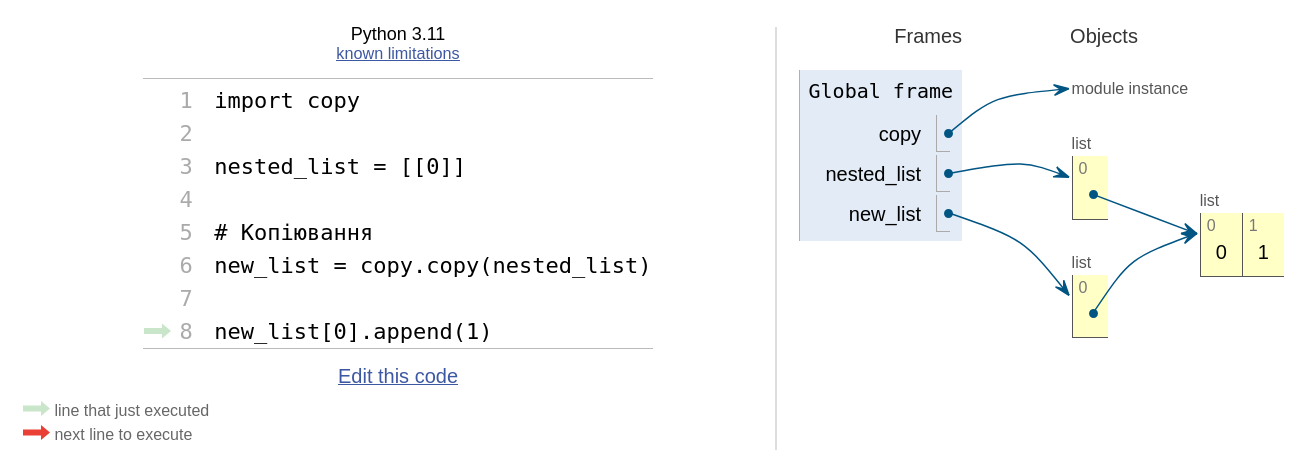
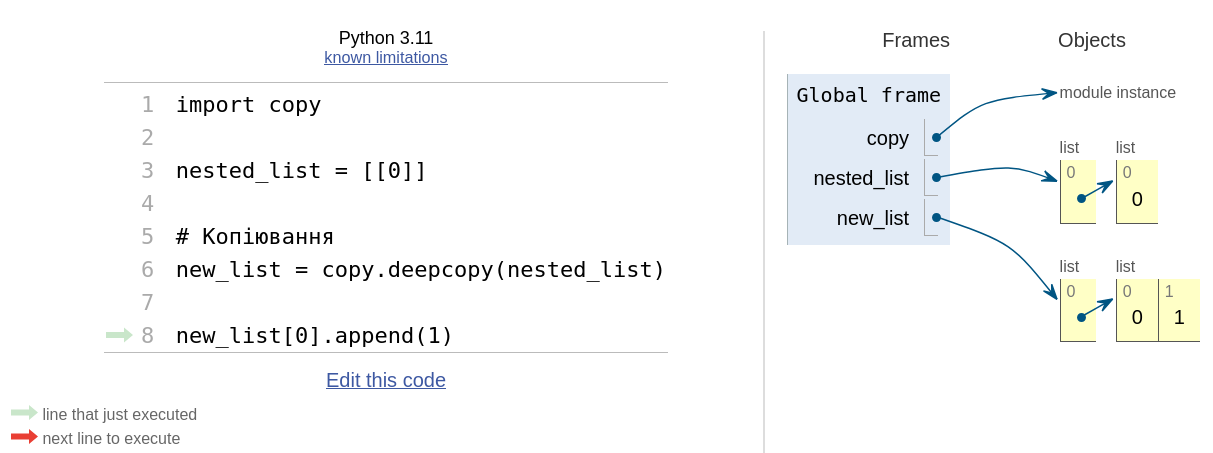

Якщо використати `deepcopy`, то кожен список буде мати свій власний об'єкт для першого елемента. Тож при зміні `new_list[0]`, нульовий елемент `nested_list` не змінюється.

Тож тепер відомі кілька способів копіювання:
- `[:]` (чи `[::]`, `[0::]` тощо),
- використати вбудований метод `copy()` (для поверхневої копії)
- обгорнути в `list()`
- списковий вираз,
- вручну перенести всі елементи.

А також спосіб "глибокого" копіювання, `copy.deepcopy`, аби точно не залишилося жодного зв'язку з попереднім об'єктом.

Чарівного вам кодування!